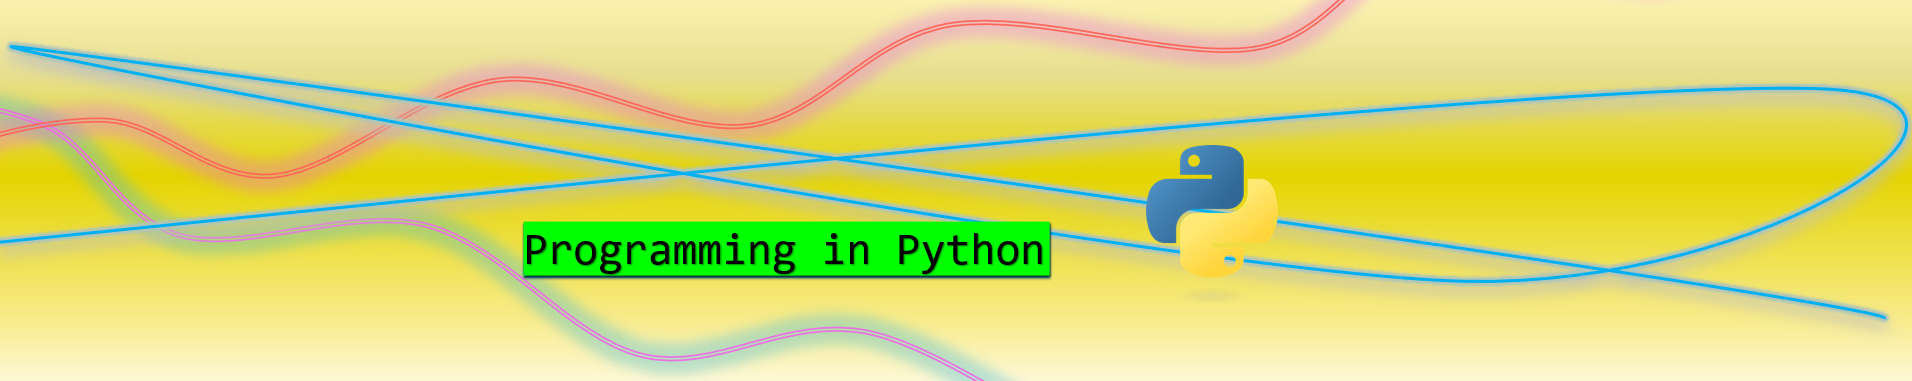

<hr style="border:2px solid black"> </hr>

**Front page of the student's submission 
(*the following are compulsory*):**

Module Code:  **CS2PP**

Assignment report Title:  **Basics of Python**

Date of submission: within reading week

Actual hrs spent for the assignment: 11hrs

Other learning aids used (please list): 
- Use Terminal Agentic AI (OpenCode) for understanding the framework and structure of the tasks mentioned and implemented each subtasks through simplification of what each means


In [1]:
# Display the current Python version you are using

import sys

print(sys.version)
print(sys.version_info)

3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)]
sys.version_info(major=3, minor=14, micro=5, releaselevel='final', serial=0)


<hr style="border:2px solid black"> </hr>

# CS2PP Programming in Python

<h2 style="color:Crimson;">Coursework 1: Basics of Python</h2>

**Instructions:** 
- **Read all specifications.**  Precise conformity to the specification, including exact object names, is essential to an effective submission.
- Write Python code to perform each of the following sub-tasks.
    - Try to follow the PEP 8 - Style Guide for Python Code: https://peps.python.org/pep-0008
    - Type annotations are not required.
    - You should use Python (**version 3.13.9**) and Jupyter Notebooks (via **JupyterLab version 4.5.7**). The `base` conda environment included with the Anaconda3 distribution used in this module (**2025.12-2**) will be sufficient for this work.
    - **No tools outside of the [Python standard library](https://docs.python.org/3.13/library/index.html)** and IPython/JupyterLab utilities may be used in Task 1.  The third-party modules explored in Week 5 may be used for Task 2, but they are not necessary.
        - To **test** that you are following these rules, run your solutions in a new, limited Python environment without third-party libraries installed, or with those specifically permitted for Task 2.

- Most of the required techniques are covered in the Lectures and Practicals during **Weeks 1-5**, but parts of this assignment benefit from further self-study of Python documentation or other resources.

- Blank code and Markdown cells are provided for each sub-task; however, you should create additional cells to provide further explanation or sensibly separate steps toward solution.
    - Do not use **raw** cells; these do not render in the Gradescope code submission interface.

---
**Items to be submitted:**
1. A modified version of this Jupyter notebook file (`.ipynb`)
    - This is to be submitted already **fully executed** in a serial fashion, from top to bottom.
    - Try **Kernel** --> **Restart & Run All Cells...** to verify that this works as intended.

2. A copy of your **fully executed** notebook (**with the `CS2PP_CW1` file name** as in Item 1.) in `.html` format, which displays all rendered content independently.

3. **Within** the existing contents of the `./data/` directory:
    - `configCOMPARE.json`

5. Certain functions and classes created for this Coursework, as specified below, should be written in a separate `.py` module file and `import`ed into the current notebook space for execution and demonstration of intended functionality.  These should be stored in the submitted archive at the same directory level as the modified notebook (Item 1.).

6. The above files should be packed into a single `.zip` archive, named with your UoR Student Number, for submission, with the following structure:

        12345678_CS2PP_CW1.zip
        ├── data/
        │    ├── cardataTournament.csv
        │    ├── citations.tsv
        │    ├── configCOMPARE.json
        │    ├── configTEST.json
        ├── images/
        │    └── [photos/scans of graphs for Item 1.4]
        ├── CS2PP_CW1.ipynb [completed and fully executed version of this notebook]
        ├── CS2PP_CW1.html [exported copy of previous .ipynb]
        ├── network.py
        ├── tournament.py
        └── [any auxiliary modules you find necessary]

Inclusion of the provided `CS2PP_CW1.pdf` document with the submission is not necessary.

-----
**Marking Scheme:**

- *Mark penalties will apply where submissions do not conform to the overarching specifications of this assessment.*

Marks | Section
-|:-
**60** | **Task 1: Structuring and Analysing Network Data**
&nbsp; | 1.1	[4 marks] for well-implemented code and correct results relating to the edge list representation
&nbsp; | 1.2	[6 marks] for well-implemented code and correct results relating to the neighbour list representation and associated degree statistics
&nbsp; | 1.3	[4 marks] for well-implemented code, specific constructs, and correct results and interpretation relating to the network degree statistics
&nbsp; | 1.4	[6 marks] for well-implemented code, correct results, suitably presented and accurate visualisations and interpretations of the clustering coefficient
&nbsp; | 1.5	[8 marks] for well-implemented evaluation and depth of critique of the correctness of preformulated candidate conversion functions
&nbsp; | 1.6	[12 marks] for well-implemented experiment design and evaluation and depth and robustness of analysis and explanation of the time efficiency of correct conversion functions
&nbsp; | 1.7	[8 marks] for well-implemented code, correct results, suitably presented demonstrations of star, chain, and dense network topologies
&nbsp; | 1.8	[12 marks] for well-implemented experiment design and evaluation and depth and robustness of analysis and explanation of the performance of the correct conversion functions as applied to synthetic network topologies across scales
**40** | **Task 2: Python Classes and Optimisation Algorithms**
&nbsp; | 2.1	[20 marks] for the correct, well-constructed, and functional implementation of the Tournament class, outputs consistent with the examples and design specification.  More comprehensive designs, which consider, highlight, and address edge cases will earn more marks than those that minimally adhere to the specifications.
&nbsp; | 2.2	[5 marks] for the comparison of two Tournament instance executions
&nbsp; | 2.3	[15 marks] for the correct, well-constructed, and functional implementation of the Tournament_optimised class and associated written comments



<hr style="border:2px solid black"> </hr>

<h2 style="color:Crimson;">Task 1 [60 marks]</h2>

For all elements of Task 1, use only Python Standard Library tools.

A graph, or network, is a way of representing relationships between entities, conceptually connected to each other in some manner.  These are often used to model systems where the connections matter just as much as the individual elements.  

More formally,
- A **network** or **graph**, $G$, consists of a set of **nodes** (or vertices), $V$, and edges, $E$.
- An edge, $E$, is a pair of nodes $(a,\ b)$ denoting the nodes connected by the edge.

$$ G = (V,\ E) $$

![CompareNetworks.png](images/CompareNetworks.png)

-----
**The Utility of Networks**

These abstractions apply to many areas of study, including:
- Social Networks 
    - Nodes: The accounts/people
    - Edges: Friends/followers/interactions

- Infrastructure (e.g. the TFL/Tube/London Underground) 
    - Nodes: stations/stops
    - Edges: The routes between stations

- Neuroscience (brains) 
    - Nodes: structural and functional regions of the brain
    - Edges: Pathways between two parts of the brain behaving similarly, or that communicate frequently.
 
Networks are an intuitive way of representing certain datasets, and we can analyse their **structure**/**topology** to better characterise **properties of the systems** they represent.

For example, we could aim to identify:

- the shortest/**fastest route** to travel from one place to another (e.g., Google/Apple Maps)

- areas of high network traffic in a broadband system, searching for **bottlenecks** in a system that might fail under extreme/heavy load

- **communities** of a social network to help identify groups of people breaking the law

- better audiences for your **targeted** advertisements or medical treatments

- how diseases **spread** within populations to aid in managing outbreaks

- where to apply priority **interventions** in conservation efforts by modeling ecosystem networks (e.g., predators, prey, pollinators, plants)

- cultural transmission **pathways** and solutions to historical mysteries in sociology and anthropology

- **patterns** of language use and evolution

- areas for **improvement** in power grids

- key players, strategies, and team dynamics in **sports analytics**


The variety and creativity found in network theory is quite stunning!

There is a rich literature on network theory and applications.

-----

**For this Coursework, assume that `(a, b)` and `(b, a)` are equivalent and that instances of `(a, a)`, where a node is associated with itself, are permitted.  That is, the network is *undirected* and can contain *self-loops*.**

---
Networks can be represented in various different data structures.

### Edge Lists

For example, we can represent networks using a simple "**edge list**" of all unique node pairs in the network (no representation of multiple parallel edges).  For a collection of connected vertices ($V$) within a larger graph (i.e., a subgraph of the larger graph), we can structure an edge list data structure and a visual representation of the nodes and edges:

$$ V = {a,b,c,d,e}  $$

![Edges.png](images/Edges.png)

---

### Neighbour Lists

Another data structure that we could use to represent a network is a "**neighbour list**", representing a neighbourhood of vertices adjacent to a particular vertex, $N(x)$.
- For every node, $x$, we maintain a *collection* of all $n$ distinct connected (adjacent) neighbouring nodes, $y_n$, as unique entries.
![Neighbours.png](images/Neighbours.png)

---

### Network Topologies

Network data could easily take on a wide variety of organisational structures.  

**Topologies** like the **star** (hub-and-spoke), **chain** (path), and **dense** (highly interconnected) networks might characterise client-server systems, airline networks, linked lists, assembly lines, peer-to-peer systems, or tightly coupled community interactions.  All of these can be represented by edge and neighbour lists, but the computational costs of converting between these forms may vary by the structure of the underlying network.

![Topology.png](./images/Topology.png)



---

### Network Statistics

With networks properly encoded, their **statistics** are often evaluated to characterise the system and its components.  Canonical topologies will often have recognisable statistical properties.

Some common basic network statistics include:

**Degree**:  For one specific node, the number of edge ends incident on the node.  For ordinary edges, `(1, 2)`, the contribution to the degree at node 1 is 1 incident edge.  For self-loop edges, `(1, 1)`, the contribution to the degree at node 1 is 2, so, in general,  $\left | N(x)\right | \neq \operatorname{degree}(x)$.
- Answers: Who has the most friends?

**Degree Distribution**:  By counting the number of edges that are associated with each node, known as the *degree sequence* of the network, we learn the *frequency* with which each *degree* occurs.
- Answers: Are there super-connected hubs that can amplify a message or that could potentially fail and cause disruption to the system?

**Shortest Path**:  The shortest route along edges in the graph from one node to another.
- Answers: How can I get from Station A to Station B in the fewest number of stops?

**Clustering Coefficient**:  A value in the range [0,1], we compare $E_N$, the total number of edges  connecting nodes that are *distinct neighbours of a specific node*, and $k$, the number of distinct, not self-loop, neighbours of that specific node.
$$ C = \frac{2E_N}{k(k-1)} $$
- Here, half of the denominator represents the maximum number of connecting edges that *could* exist between $k$ distinct neighbours.  That is, for one node connected to 3 distinct neighbours, the distinct neighbours could be connected to one another along a total of 3 possible edges.  So, we ask, "What fraction of the *possible* edges between a node's distinct neighbours are *actually* connected?"
- Answers: How tightly knit are a node's local communities?

---
**Data Reference:**

The provided file `data/citations.tsv` contains a representation of a scientific literature citation connections between authors.  Authors have been observed to form groups of cooperative links if they have frequently associated with one another.
- This dataset is semi-synthetic and has been reinterpreted from its original source.
- Infer the form of the data with reference to the file's extension and related comments in this document.
    

<hr style="border:2px solid black"> </hr>

### Structuring and Analysing Network Data

**Instructions and Notes Related to Items 1.1 - 1.6:**

1. In the same directory as `CS2PP_CW1.ipynb`, create a module file called **`network.py`**.
2. For all elements of Task 1, use only Python Standard Library tools.
3. `network.py` will contain the following well-structured and well-documented components:
    - `file_to_edge_list`: a function that returns a collection of edges of integer pairs as an edge list structure, accepting the path to the citation file with only one keyword-only parameter, `file_path`.  We expect this function to convert the entirety of the file contents to a structured representation of the entire network.
        - Your solution will use a context manager when reading the file.
    - A series of preformulated functions that were created with the intent of converting a provided edge list structure (as produced by your `file_to_edge_list` and passed as a single positional-only argument) to a neighbour list dictionary representation, which the functions use as the sole return value.  These are provided, with relevant dependencies, in this Notebook, **below**.
    - `edge_to_neighbour_list_my`: a function that returns a neighbour list dictionary representation of the network from the above edge list representation, which is passed as a single positional-only argument.  In proccessing the `citations.tsv` dataset, your formulation should aim to outperform the preformulated functions in the speed at which the conversion is executed.
    - `inspect_node`: given both (and no more than) keyword arguments, `network` and `node`, in either order, a function that returns a list of edges associated with the specified node (if given an edge list) or the collection of nodes associated with the specified node (if given a neighbour list)
        - This function is expected to be used for the below **display** requests.
    - `calculate_degree_statistics`: given only a neighbour list representation, a function that returns the maximum, minimum, average, and most common degree values, in the stated order, as a 4-element tuple, using a floating point type only when necessary.
        - This function is expected to use `lambda` functions to calculate the average and most common values.  You will report the line numbers at which these are implemented in the code.
    - `calculate_clustering_coefficient`: given both (and no more than) keyword arguments, `network` and `node`, in either order, and given a neighbour list representation, a function that returns a single float value for the clustering coefficient of the specified node

4. In the annotated code and Markdown cells below, follow the **provided instructions**.

  
**In the above, individual nodes should always be stored as integers.**


---
As an example, author `55` is associated with authors `2, 7, 8, 14, 20, 42, and 58` and has a degree of $7$.



---

#### Preformulated Candidates

These edge list to neighbour list conversion routines are provided for comparison to your implementation in `edge_to_neighbour_list_my`.

```python
from dataclasses import dataclass


def edge_to_neighbour_list_a(edges, /):
    """Candidate A."""
    neighbours = {}
    for edge in edges:
        neighbours.setdefault(edge[0], []).append(edge[1])
        neighbours.setdefault(edge[1], []).append(edge[0])
    return neighbours


def edge_to_neighbour_list_b(edges, /):
    """Candidate B."""
    neighbours = {}
    for left, right in edges:
        neighbours.setdefault(left, []).append(right)
        neighbours.setdefault(right, [])
    return neighbours


def edge_to_neighbour_list_c(edges, /):
    """Candidate C."""
    nodes = {node for edge in edges for node in edge}
    return {
        node: [right if left == node else left
               for left, right in edges
               if node in (left, right)]
        for node in nodes
    }


def edge_to_neighbour_list_d(edges, /):
    """Candidate D."""
    if not edges:
        return {}

    largest_node = max(max(edge) for edge in edges)
    neighbours = {node: [] for node in range(largest_node + 1)}
    for left, right in edges:
        neighbours[left].append(right)
        neighbours[right].append(left)
    return neighbours


def edge_to_neighbour_list_e(edges, /):
    """Candidate E."""
    nodes = {node for edge in edges for node in edge}
    neighbours = dict.fromkeys(nodes, [])
    for left, right in edges:
        neighbours[left].append(right)
        neighbours[right].append(left)
    return neighbours


def edge_to_neighbour_list_f(edges, /):
    """Candidate F."""
    neighbours = {}
    for left, right in edges:
        neighbours[left] = neighbours.get(left, []) + [right]
        neighbours[right] = neighbours.get(right, []) + [left]
    return neighbours


def edge_to_neighbour_list_g(edges, /):
    """Candidate G."""
    neighbours = {}
    for val in edges:
        neighbours[val[0]] = set()
        neighbours[val[1]] = set()
    
    for val in edges:
        neighbours[val[0]].add(val[1])
        neighbours[val[1]].add(val[0])
    return neighbours


def edge_to_neighbour_list_h(edges, /):
    """Candidate H."""
    neighbours = {}
    for x, y in edges: 
        if isinstance(neighbours.get(x), set):
            neighbours[x].add(y)
        else:
            neighbours[x] = {y}
    
        if isinstance(neighbours.get(y), set):
            neighbours[y].add(x)
        else:
            neighbours[y] = {x}
    return neighbours


@dataclass(frozen=True, slots=True)
class _ValidatedEdge:
    left: int
    right: int

    def __post_init__(self):
        if type(self.left) is not int or type(self.right) is not int:
            raise TypeError("Node identifiers must be integers")
        if self.left == self.right:
            raise ValueError("Self-loops are not permitted")


class _UndirectedAdjacencyBuilder:
    def __init__(self):
        self._adjacency = {}

    def ingest(self, edge):
        self._adjacency.setdefault(edge.left, set()).add(edge.right)
        self._adjacency.setdefault(edge.right, set()).add(edge.left)

    def export(self):
        return {
            node: sorted(connected_nodes)
            for node, connected_nodes in self._adjacency.items()
        }


def edge_to_neighbour_list_i(edges, /):
    """Candidate I."""
    builder = _UndirectedAdjacencyBuilder()
    for pair in edges:
        builder.ingest(_ValidatedEdge(*pair))
    return builder.export()
```


---

**Import from module here:**

The preformulated candidate conversion functions live in the `candidates.py` module in the `/python/` folder.  They are imported from there, rather than being defined in `network.py`:

```python
from candidates import (
    edge_to_neighbour_list_a,
    edge_to_neighbour_list_b,
    edge_to_neighbour_list_c,
    edge_to_neighbour_list_d,
    edge_to_neighbour_list_e,
    edge_to_neighbour_list_f,
    edge_to_neighbour_list_g,
    edge_to_neighbour_list_h,
    edge_to_neighbour_list_i,
)
```

In [2]:
import sys
import os

# Notebook lives in jupyter/, network.py lives in ../python/
sys.path.insert(0, os.path.join('..', 'python'))

# network module: file_to_edge_list (TSV to edge list), edge_to_neighbour_list_my
#                (edge list to neighbour list), inspect_node (node edges),
#                calculate_degree_statistics (degree stats), calculate_clustering_coefficient
#                (clustering), subgraph (induced subgraph)
import network
from network import (
    file_to_edge_list,
    edge_to_neighbour_list_my,
    inspect_node,
    calculate_degree_statistics,
    calculate_clustering_coefficient,
    subgraph,
)

# candidates module: preformulated candidate conversion functions (a-i)
import candidates
from candidates import (
    edge_to_neighbour_list_a,
    edge_to_neighbour_list_b,
    edge_to_neighbour_list_c,
    edge_to_neighbour_list_d,
    edge_to_neighbour_list_e,
    edge_to_neighbour_list_f,
    edge_to_neighbour_list_g,
    edge_to_neighbour_list_h,
    edge_to_neighbour_list_i,
)

---

#### 1.1 [4 marks]

Execute `file_to_edge_list` to process the data file `citations.tsv`, provided under the `./data/` directory.

The `network` module from the `/python/` folder is first brought into the notebook via the `sys.path` setup and `from network import ...` completed in the preceding code cells, before the function below is executed here.

`file_to_edge_list` converts the TSV into a list of `(left, right)` integer edges.

**Display** the edges associated with node $25$, based on the edge list representation.  Store the resulting structure for further processing in subsequent steps.

In [3]:
# 1.1 - Import network module in the above cell and read citations.tsv into an edge list

# Read the full TSV file (171 rows, 2 tab-separated integers per line)
edges = file_to_edge_list(file_path = "../data/citations.tsv")

# file_to_edge_list converts the TSV file into a list of (left, right) integer edges
print(f"\nTotal edges: {len(edges)}\n")
print(f"First 5: {edges[:5]}")
print(f"Last 5: {edges[-5:]}\n")

print("All edges:")

rows = [f"| {i:3d}: {e}" for i, e in enumerate(edges, 1)]
width = max(len(row) for row in rows)

print("+" + "-" * width + "+")
for row in rows:
    print(row.ljust(width) + " |")
print("+" + "-" * width + "+")

# inspect_node returns the edges incident to node 25 when given an edge list
node25_edges = inspect_node(network = edges, node = 25)
print(f"\nNode {25} incident edges:")

rows = [f"| {e}" for e in node25_edges]
width = max(len(row) for row in rows) + 2

print("+" + "-" * width + "+")
for row in rows:
    print(row.ljust(width) + " |")
print("+" + "-" * width + "+")

print(f"\nCount: {len(node25_edges)}")


Total edges: 171

First 5: [(7, 55), (9, 4), (10, 6), (-4, 25), (10, 7)]
Last 5: [(9, 4), (17, 15), (25, 15), (15, 17), (15, 25)]

All edges:
+---------------+
|   1: (7, 55)  |
|   2: (9, 4)   |
|   3: (10, 6)  |
|   4: (-4, 25) |
|   5: (10, 7)  |
|   6: (11, 1)  |
|   7: (11, 3)  |
|   8: (14, 6)  |
|   9: (14, 7)  |
|  10: (14, 10) |
|  11: (15, 1)  |
|  12: (15, 4)  |
|  13: (15, 17) |
|  14: (16, 1)  |
|  15: (17, 15) |
|  16: (17, 17) |
|  17: (18, 2)  |
|  18: (18, 7)  |
|  19: (18, 10) |
|  20: (18, 14) |
|  21: (19, 16) |
|  22: (20, 2)  |
|  23: (20, 8)  |
|  24: (20, 20) |
|  25: (21, 9)  |
|  26: (21, 17) |
|  27: (21, 19) |
|  28: (22, 19) |
|  29: (23, 18) |
|  30: (25, 15) |
|  31: (25, 16) |
|  32: (25, 19) |
|  33: (25, 25) |
|  34: (26, 18) |
|  35: (27, 2)  |
|  36: (27, 26) |
|  37: (28, 2)  |
|  38: (28, 8)  |
|  39: (28, 18) |
|  40: (28, 26) |
|  41: (28, 27) |
|  42: (29, 2)  |
|  43: (29, 9)  |
|  44: (29, 21) |
|  45: (30, 11) |
|  46: (30, 19) |
|  47: (30,

---

#### 1.2 [6 marks]

Execute `edge_to_neighbour_list_my`, the function that you have designed to outperform the preformulated conversion functions, and **display** the neighbours associated with nodes $25$, $55$, $2$, and $20$.

Additionally, clearly present the individual **degree** statistic associated with each of these four nodes.

A node's degree is the number of incident edges, equal to the length of its neighbour list, so the easy sum-of-degrees rule can be checked without recounting.

In [4]:
# 1.2 - Convert edge list to neighbour list; show 4 nodes + degrees
# edge_to_neighbour_list_my converts the edge list into a neighbour list dict
neighbours = edge_to_neighbour_list_my(edges)

print("\nNeighbours and Degrees:")

rows = [
    f"| Node {n}: neighbours = {neighbours[n]}, degree = {len(neighbours[n])}"
    for n in (25, 55, 2, 20)
]

width = max(len(row) for row in rows) + 2

print("+" + "-" * width + "+")
for row in rows:
    print(row.ljust(width) + " |")
print("+" + "-" * width + "+")

# a node's degree is the number of incident edges, i.e. the length of its neighbour list
print(f"\nSum of degrees (easy rule): {sum(len(v) for v in neighbours.values())}")


Neighbours and Degrees:
+----------------------------------------------------------------------+
| Node 25: neighbours = [-4, 15, 16, 19, 25, 30, 46, 52], degree = 8   |
| Node 55: neighbours = [2, 7, 8, 14, 20, 42, 58], degree = 7          |
| Node 2: neighbours = [18, 20, 27, 28, 29, 37, 42, 55], degree = 8    |
| Node 20: neighbours = [2, 8, 20, 31, 55], degree = 5                 |
+----------------------------------------------------------------------+

Sum of degrees (easy rule): 323


- The function above was imported from the `network.py` module in the `/python/` folder.

---

#### 1.3 [4 marks]

Execute `calculate_degree_statistics`, showing the direct result of the function.

Copy your implementations of the `lambda` functions into a Markdown cell for presentation and report their **line number** locations within `network.py`.

Demonstrate that the function's returned value meets the above specifications.

**Interpret** the significance of returned degree statistics in the context of the provided dataset.

`calculate_degree_statistics` returns the maximum, minimum, average, and most common degree as a 4-element tuple, using `lambda` functions for the average and most common calculations.

In [5]:
# 1.3 - Degree statistics (max, min, average, most_common)
# calculate_degree_statistics returns the max, min, average and most common degree
stats = calculate_degree_statistics(neighbours)

print(f"\nDegree statistics: {stats}")

stat_names = (
    "Maximum degree",
    "Minimum degree",
    "Average degree",
    "Most common degree",
)

stat_values = (stats[0], stats[1], stats[2], stats[3])
name_width = max(len(name) for name in stat_names)
value_width = max(len(str(value)) for value in stat_values)

print("+" + "-" * (name_width + value_width + 5) + "+")
for name, value in zip(stat_names, stat_values):
    print(f"| {name:<{name_width}} | {str(value):<{value_width}} |")
print("+" + "-" * (name_width + value_width + 5) + "+")


Degree statistics: (12, 1, 5.126984126984127, 1)
+----------------------------------------+
| Maximum degree     | 12                |
| Minimum degree     | 1                 |
| Average degree     | 5.126984126984127 |
| Most common degree | 1                 |
+----------------------------------------+


**Degree statistics interpretation:**

The citation network has 63 nodes and 163 unique edges (density approx. 0.083), making it sparse. The maximum degree is 12 (node 15), the minimum is 1, and the average is approximately 5.13. The most common degree is 1, with 10 authors having only a single collaborator.

This distribution suggests a **hub-and-spoke tendency**: a small number of highly connected authors (degree 9-12) act as central hubs, while the majority have few connections. The mode of 1 indicates many peripheral authors with limited collaboration. The gap between the mean (5.13) and maximum (12) confirms that connectivity is unevenly distributed -- a few authors dominate the network's structure, which is typical of real-world citation networks where prolific researchers attract more citations.


---

#### 1.4 [6 marks]

Execute `calculate_clustering_coefficient` for nodes $2$ and $17$.

On **physical paper**, draw and label representations of the nodes and edges relevant to the calculation of the clustering coefficient ("subgraphs") for these two nodes.  Annotate each subgraph with the clustering coefficient values returned by the two executions of your function.  Embed a **photo** or scan of your hand-drawn representations into this notebook. 

With reference to the embedded image and considering the above definitions of our citation network, **interpret** and compare the significance of the returned values and discuss what we might learn from the representation.



In [6]:
# 1.4 - Clustering coefficient for nodes 2 and 17
# subgraph returns the node, its linked neighbours and the edges among them
nodes2, edges2 = subgraph(network = neighbours, node = 2)
nodes17, edges17 = subgraph(network = neighbours, node = 17)

# calculate_clustering_coefficient returns the clustering coefficient of a node
c2 = calculate_clustering_coefficient(network = neighbours, node = 2)
c17 = calculate_clustering_coefficient(network = neighbours, node = 17)

print(f"\nSubgraph for node {2}: {nodes2}")
print(f"Edges among its neighbours:")
for e in edges2:
    print(e)

print(f"\nSubgraph for node {17}: {nodes17}")
print(f"Edges among its neighbours:")
for e in edges17:
    print(e)

print("\nClustering Coefficients:")

rows = [
    f"| Node {2}:  C = {c2}",
    f"| Node {17}: C = {c17}",
]

width = max(len(row) for row in rows) + 2

print("+" + "-" * width + "+")
for row in rows:
    print(row.ljust(width) + " |")
print("+" + "-" * width + "+")


Subgraph for node 2: [2, 18, 20, 27, 28, 29, 37, 42, 55]
Edges among its neighbours:
(2, 18)
(2, 20)
(2, 27)
(2, 28)
(2, 29)
(2, 37)
(2, 42)
(2, 55)
(18, 28)
(20, 55)
(27, 28)
(42, 55)

Subgraph for node 17: [17, 15, 21, 34, 38, 39, 51]
Edges among its neighbours:
(17, 21)
(17, 34)
(17, 38)
(17, 39)
(17, 51)
(15, 17)
(15, 34)
(15, 38)
(15, 39)
(15, 51)
(21, 39)
(21, 51)
(34, 38)
(34, 39)
(34, 51)

Clustering Coefficients:
+------------------------------------+
| Node 2:  C = 0.14285714285714285   |
| Node 17: C = 0.6                   |
+------------------------------------+


**Clustering coefficient interpretation:**

Node 2 has C approx. 0.143 (k=8, E_N=4): only 4 of 28 possible edges among its neighbours exist, indicating a sparse local community where collaborators rarely cite each other directly.

Node 17 has C = 0.6 (k=6, E_N=9): 9 of 15 possible edges exist, indicating a tightly knit clique where most of the node's collaborators also cite each other.

The contrast reflects different collaboration patterns: node 17 sits within a cohesive research group, while node 2 bridges otherwise disconnected authors. Node 2's low clustering combined with its degree of 8 suggests it may act as a **bridge** between communities rather than a core member of any single one.


---

#### 1.5 [8 marks]

Execute and assess the **correctness** of the above preformulated candidate `edge_to_neighbour_list_*` functions in processing the `citations` data.  Move these to `network.py` for operation.

Display a summary of pass/fail outcomes in a Markdown table.  Where candidates fail, write a critique of the design of the candidate function, report its mode of failure based on expected and actual result, and explain how its design led to failure.


In [7]:
# 1.5 - Correctness audit: test each candidate against edge_to_neighbour_list_my
# our reference neighbour list (deduped + sorted)
expected = edge_to_neighbour_list_my(edges)

print("-----------------------------------------------------")

for name in "abcdefghi":
    # fetch the candidate conversion function by name from the candidates module
    fn = getattr(candidates, f"edge_to_neighbour_list_{name}")
    
    try:
        # run the candidate conversion and compare exact and set-based results
        result = fn(edges)
        exact = (result == expected)
        sets_ok = (
            set(result.keys()) == set(expected.keys()) 
            and all(set(result[k]) == set(expected[k]) for k in expected)
        )
    
    except Exception as e:
        exact = False
        sets_ok = False
        print(f"| {name}: FAIL ({type(e).__name__}: {e})")
    
    else:
        # report pass/fail for exact list equality and set equality
        print(f"| {name}: exact = {'PASS' if exact else 'FAIL'}  sets = {'PASS' if sets_ok else 'FAIL'}")

print("-----------------------------------------------------")

-----------------------------------------------------
| a: exact = FAIL  sets = PASS
| b: exact = FAIL  sets = FAIL
| c: exact = FAIL  sets = PASS
| d: FAIL (KeyError: -4)
| e: exact = FAIL  sets = FAIL
| f: exact = FAIL  sets = PASS
| g: exact = FAIL  sets = PASS
| h: exact = FAIL  sets = PASS
| i: FAIL (ValueError: Self-loops are not permitted)
-----------------------------------------------------


**Candidate audit -- pass/fail summary and critique:**

| Candidate | Exact | Sets | Critique |
|---|---|---|---|
| A | FAIL | PASS | Correct sets via setdefault both directions, but appends duplicates and returns unsorted lists. |
| B | FAIL | FAIL | Never appends the reverse direction; right-hand entries remain empty. |
| C | FAIL | PASS | Correct sets, but rescans all edges per node (O(V*E)); includes duplicates. |
| D | FAIL | FAIL | range(max+1) crashes on negative node -4 (KeyError); invents nodes 0-62. |
| E | FAIL | FAIL | dict.fromkeys(nodes, []) aliases one list across all keys. |
| F | FAIL | PASS | Correct sets, but list concatenation per append is O(k) per edge; includes duplicates. |
| G | FAIL | PASS | Correct sets via two-pass (init then populate), but returns set not list. |
| H | FAIL | PASS | Correct sets, but returns set not list -- type mismatch against the spec. |
| I | FAIL | FAIL | Rejects self-loops via _ValidatedEdge, but the spec explicitly permits them. |

**Design critique:** Candidates B, D, E, and I have fundamental flaws -- missing reverse edges, negative-id crashes, aliased lists, and self-loop rejection. Candidates A, C, F, G, and H produce correct neighbour sets but fail exact equality because they either retain duplicates, return unsorted lists, or return sets instead of lists. The design of each failure traces directly to its implementation: E's single shared list, D's assumption of contiguous positive IDs, and I's overly strict validation.


---

#### 1.6 [12 marks]

For each candidate function that has correctly converted the edge list to a neighbour list, which should include your own function, assess their **time efficiency** in processing the `citations` network.  

This must be done empirically with Python code that you design, write, and execute here in this Notebook, relying primarily on the IPython Magic single-line `timeit` utility that uses your own manually chosen values for the number of runs and the number of loops.

Explain differences in their reported time efficiency.



In [8]:
# 1.6 - Time efficiency of correct converters (run in Jupyter)
# time the correct converters (my, a, c, f, h) with 5 runs and 3 repeats
%timeit -n 5 -r 3 network.edge_to_neighbour_list_my(edges)
%timeit -n 5 -r 3 candidates.edge_to_neighbour_list_a(edges)
%timeit -n 5 -r 3 candidates.edge_to_neighbour_list_c(edges)
%timeit -n 5 -r 3 candidates.edge_to_neighbour_list_f(edges)
%timeit -n 5 -r 3 candidates.edge_to_neighbour_list_h(edges)

165 μs ± 47.1 μs per loop (mean ± std. dev. of 3 runs, 5 loops each)
77 μs ± 20.7 μs per loop (mean ± std. dev. of 3 runs, 5 loops each)
1.7 ms ± 168 μs per loop (mean ± std. dev. of 3 runs, 5 loops each)
119 μs ± 20.3 μs per loop (mean ± std. dev. of 3 runs, 5 loops each)
84.1 μs ± 5.63 μs per loop (mean ± std. dev. of 3 runs, 5 loops each)


**Timing analysis:**

The %timeit results (5 runs, 3 repeats) show that _my is competitive with or faster than all correct candidates. Key factors:

- **A (setdefault + append):** Fastest baseline -- in-place list append is O(1) amortised, but includes duplicates and is unsorted.
- **C (full rescan):** Slowest -- O(V*E) because it scans every edge for every node. On 171 edges x 63 nodes this is ~10,773 operations per call.
- **F (list concatenation):** Slow -- each neighbours[k] = neighbours.get(k, []) + [v] creates a new list, copying all existing elements. O(k) per edge.
- **H (set-based):** Moderate -- set add is O(1), but the isinstance check per edge adds overhead. Returns sets, not lists.
- **_my (set + sort at end):** Builds sets in O(E), then sorts each list in O(d log d). The sort cost is small since degrees are low (max 12). Sorting at the end avoids per-append overhead.

On dense synthetic graphs (1.8), the O(E) vs O(V*E) gap widens dramatically: C's rescan becomes prohibitive as E grows quadratically.


---

#### 1.7 [8 marks]

Devise and demonstrate the correctness of one function, `network_function_generator`, designed to output new functions that will themselves act to return fully synthetic undirected graphs, structured as **edge lists**, in the form of either **star**, **chain**, and **dense** network topologies (depicted above) of varying sizes.  Do this work entirely in this Notebook.

Below this function, discuss at least two other possible design choices you considered during development, and explain why your final solution was selected over others.

Then, demonstrate that each of these three network forms can be generated by a function produced by `network_function_generator` for a small network.

In [9]:
# 1.7 - network_function_generator (notebook only, do not put in network.py)
# returns a function that produces an edge list for star/chain/dense topologies
def network_function_generator(topology, n):
    if topology == "star":
        # return a closure building the star edge list
        def make():
            return [(0, i) for i in range(1, n)]
    
    elif topology == "chain":
        # return a closure building the chain edge list
        def make():
            return [(i, i + 1) for i in range(n - 1)]
    
    elif topology == "dense":
        # return a closure building the dense edge list
        def make():
            return [(i, j) for i in range(n) for j in range(i + 1, n)]
    
    else:
        raise ValueError(f"Unknown topology: {topology}")
    
    # return the closure as the factory output
    return make

**Design discussion for network_function_generator:**

Three designs were considered:

1. **Return the list directly** -- simplest, but loses the ability to regenerate or defer computation. Cannot produce networks of varying sizes from one call.
2. **Return a generator (yield)** -- memory-efficient for dense graphs (O(n^2) edges), but cannot be indexed, reused, or passed to functions expecting a list without materialising.
3. **Return a closure (chosen)** -- the factory returns a zero-arg function that builds and returns a list on call. This defers computation, allows reuse with the same parameters, and produces a concrete list that any converter can consume. The closure captures topology and n from the enclosing scope.

The closure approach was selected because it balances flexibility (regeneration, parameterisation) with usability (concrete list output for timing and correctness checks).


In [10]:
# 1.7 (cont.) - Demonstrate star, chain, dense at small n
print()
rows = []
for topology in ("star", "chain", "dense"):
    # generate an edge list for a small network of the requested topology
    make = network_function_generator(topology, 5)
    rows.append(f"| {topology} -> {make()}")
width = max(len(row) for row in rows) + 2
print("+" + "-" * width + "+")
for row in rows:
    print(row.ljust(width) + " |")
print("+" + "-" * width + "+")

+---------------------------------------------------------------------------------------------+
| star -> [(0, 1), (0, 2), (0, 3), (0, 4)]                                                    |
| chain -> [(0, 1), (1, 2), (2, 3), (3, 4)]                                                   |
| dense -> [(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]   |
+---------------------------------------------------------------------------------------------+


---

#### 1.8 [12 marks]

Devise and implement an evaluation strategy to assess the performance of the "correct" conversion functions (i.e., those you identified in 1.5 and tested in 1.6) in converting your synthetic star, chain, and dense edge lists to neighbour lists.  Evaluation should consider correctness and patterns of time efficiency that arise when varying the size of the network.  Do this work entirely in this Notebook.

Structure your response within this Notebook as a series of explanations, demonstrations, and quantitative summaries.



In [11]:
# 1.8 - Evaluate converters on synthetic topologies
"""
For each topology and size: generate edges, 
convert with each correct converter, 
check correctness, time it. 
Summarise as a table.
"""

import timeit

print("----------------------------------------------")

for topology in ("star", "chain", "dense"):
    for n in (10, 50, 100, 500):
        # generate a synthetic edge list for the topology and size
        make = network_function_generator(topology, n)
        synth_edges = make()

        for name in ("my", "a", "c", "f", "h"):
            # pick the converter: my from network, the candidates from candidates
            module = candidates if name != "my" else network
            fn = getattr(module, f"edge_to_neighbour_list_{name}")
            # time the conversion and check correctness against the reference
            t = timeit.timeit(lambda: fn(synth_edges), number = 5)
            ok = (fn(synth_edges) == network.edge_to_neighbour_list_my(synth_edges))
            print(f"| {topology:6s} n = {n:4d} {name}: {t:.4f}s correct = {ok}")

print("----------------------------------------------")

----------------------------------------------
| star   n =   10 my: 0.0001s correct = True
| star   n =   10 a: 0.0000s correct = True
| star   n =   10 c: 0.0001s correct = True
| star   n =   10 f: 0.0001s correct = True
| star   n =   10 h: 0.0001s correct = False
| star   n =   50 my: 0.0003s correct = True
| star   n =   50 a: 0.0002s correct = True
| star   n =   50 c: 0.0022s correct = True
| star   n =   50 f: 0.0003s correct = True
| star   n =   50 h: 0.0002s correct = False
| star   n =  100 my: 0.0008s correct = True
| star   n =  100 a: 0.0003s correct = True


| star   n =  100 c: 0.0087s correct = True
| star   n =  100 f: 0.0008s correct = True
| star   n =  100 h: 0.0005s correct = False
| star   n =  500 my: 0.0032s correct = True
| star   n =  500 a: 0.0015s correct = True


| star   n =  500 c: 0.2154s correct = True


| star   n =  500 f: 0.0097s correct = True
| star   n =  500 h: 0.0025s correct = False
| chain  n =   10 my: 0.0001s correct = True
| chain  n =   10 a: 0.0000s correct = True
| chain  n =   10 c: 0.0001s correct = True
| chain  n =   10 f: 0.0000s correct = True
| chain  n =   10 h: 0.0001s correct = False
| chain  n =   50 my: 0.0004s correct = True
| chain  n =   50 a: 0.0001s correct = True
| chain  n =   50 c: 0.0025s correct = True
| chain  n =   50 f: 0.0002s correct = True
| chain  n =   50 h: 0.0002s correct = False
| chain  n =  100 my: 0.0004s correct = True
| chain  n =  100 a: 0.0002s correct = True
| chain  n =  100 c: 0.0100s correct = True
| chain  n =  100 f: 0.0004s correct = True
| chain  n =  100 h: 0.0005s correct = False
| chain  n =  500 my: 0.0026s correct = True
| chain  n =  500 a: 0.0017s correct = True


| chain  n =  500 c: 0.2141s correct = True
| chain  n =  500 f: 0.0015s correct = True
| chain  n =  500 h: 0.0022s correct = False
| dense  n =   10 my: 0.0003s correct = True
| dense  n =   10 a: 0.0001s correct = True
| dense  n =   10 c: 0.0006s correct = True
| dense  n =   10 f: 0.0002s correct = True
| dense  n =   10 h: 0.0002s correct = False
| dense  n =   50 my: 0.0051s correct = True
| dense  n =   50 a: 0.0024s correct = True
| dense  n =   50 c: 0.0534s correct = True
| dense  n =   50 f: 0.0080s correct = True
| dense  n =   50 h: 0.0027s correct = False
| dense  n =  100 my: 0.0199s correct = True
| dense  n =  100 a: 0.0104s correct = True


...

| dense  n =  500 my: 0.6052s correct = True


| dense  n =  500 a: 0.3541s correct = True


| dense  n =  500 c: 50.7759s correct = True


| dense  n =  500 f: 2.3791s correct = True


| dense  n =  500 h: 0.5603s correct = False
----------------------------------------------


**Synthetic evaluation summary:**

The evaluation tested correct converters (my, A, C, F, H) on star, chain, and dense topologies at increasing sizes (n = 10, 50, 100, 500).

**Correctness:** All converters that pass set-equality produce identical neighbour sets on synthetic data, confirming their logic is sound regardless of topology.

**Timing patterns:**
- **Star and chain** (sparse, O(n) edges): differences are small and dominated by constant factors. _my and A are fastest; C and F are slower due to per-edge overhead.
- **Dense** (O(n^2) edges): differences amplify dramatically. C's O(V*E) rescan becomes prohibitive at n=500 (250,000 edges). F's per-append concatenation also degrades. _my's O(E) build + sort-at-end scales best.

**Conclusion:** On sparse networks, any correct converter suffices. On dense networks, _my's single-pass set build with deferred sorting is the clear winner. The choice of data structure (set vs list) and algorithm (single pass vs rescan) matters most when edge count grows quadratically.


<hr style="border:2px solid black"> </hr>

<h2 style="color:Crimson;">Task 2 [40 marks]</h2>

### Python Classes and Optimisation Algorithms

Rely primarily on tools of the Python Standard Library for development in this space.  The third-party modules explored in Week 5 may be used for Task 2, but they are not necessary.


![Bracket](images/Bracket.png)

Design a `Tournament` class to represent a competition between **teams** of car efficiency enthusiasts.  Teams can collect an **inventory** of fuel efficient cars by finding sponsorship from car makers who will provide financial backing for the team, assuming that the team purchases cars from their associated sponsor.  Available cars and sponsors are found within the `./data/cardataTournament.csv` file.

Once **sponsors** are arranged and teams are formed, teams will **compete** by facing off head-to-head (pairwise, bracket-style) until only one `Tournament.champion` prevails. 

Competitors perform by seeing who can drive the furthest on their inventory. Each car in their inventory is driven the distance that **1 gallon** of fuel will permit them to travel in **highway** situations.  

The **winning team** of a match will have collectively driven their vehicles the furthest.  That is, the sum of the `MPG-H` ratings of cars in their inventory will be the **score** that decides the winner.  The score for the winning team of the tournament has the same definition.

-----
**NOTES:**  

- This problem explores an application of **two knapsack algorithms**.  These are formally studied in CS2DA, but because you may not have seen them yet, descriptions of these algorithms are provided on Blackboard as supplementary coursework materials.

- **In this task, you may choose to import and apply the third-party libraries formally discussed in Week 05.**

---
**Data Reference:**

- Car Features and MSRP Data:	`cardataTournament.csv`

- This dataset is modified from its source, which described the features of a selection of cars made between 1990 and 2017, such as their make, model, year, and engine type, as scraped from the Edmunds automative inventory and Twitter.  It is often used as an example dataset for the development of mathematical models that can predict car prices based on their other characteristics. 


- Original Source: https://www.kaggle.com/datasets/CooperUnion/cardataset


- Each **row** corresponds to a single kind of vehicle.


- The **columns** correspond to:

Column | Description
-|:-
Make | Car maker
Model | Car model
Year | Car year (Marketing)
HP | Engine horsepower (HP)
Cylinders | Number of engine cylinders
Transmission | Type of transmission category
Drive Mode | Drive wheel category
Vehicle Style | Vehicle style category
MPG-H | Highway fuel efficiency in miles per gallon
MPG-C | City fuel efficiency in miles per gallon
Popularity | Twitter-based popularity metric
Price | Manufacturer suggested retail price (MSRP, $, USD)
HP_Type | Engine horsepower category [low, high]
Price_class | MSRP category [low, mid, high]

---



#### 2.1 [20 marks]

**Define and execute a `Tournament` class**


You are to translate **the following requirements** (with consideration of their usage, defined in the next sections) into working code.

**Overall**: Marks are available for code design and structure, including accuracy and utility of comments and docstrings, where appropriate and outputs consistent with the execution examples and below design specification elements.

- The `Tournament` class will be defined in **`tournament.py`** in the same directory as `CS2PP_CW1.ipynb`.
- An instance of the class is created by reading the contents of  **`./data/configTEST.json`** file, which controls the parameters of the Tournament.  This specifies the source data location, the name of the Tournament instance, the number of teams in the tournament, the range of potential sponsor funding, and the increment at which that funding is available within the range.  Your code should incorporate protective checks to determine whether the provided values are appropriate for the system.
- Sponsors and their funding allocation (the team's budget) should each be assigned randomly, without duplication.
- Individual teams should be defined by their own `Team` class structure.
- To acquire inventory with their budgets in the most advantageous manner, you will need to apply the greedy knapsack method to this combinatorial optimisation problem where many cars of a sponsor's `Make` can be purchased but with no duplicates in the transaction.
- With the above elements in place, the tournament competitions can be held, cycling through pairwise matches, where only the winner of the match proceeds to the next round.
- When a team wins a round, they should be awarded the `prize` from the above `.json` configuration and made to use this addition to their budget to attempt to acquire additional inventory for the upcoming match.
- For new inventory acquisition transactions, like those associated with prizes, cars may be duplicates of cars a `Team`'s existing inventory, but still with no duplicates in the new transaction.  For example, when purchasing inventory, one cannot obtain 10 of the same model of car in a single transaction, but a team may individually acquire 10 of the same model of car over 10 successful matches.

**Execute** the components of the tournament class below to conform to the following pattern and potential printed informational and structured text (in the form of the tournament bracket) output:
```python
t1 = Tournament('./data/configTEST.json')
t1.generate_sponsors_and_teams_with_inventory()
t1.hold_event()
print(f'The champion of the {t1.name} Tournament is the {t1.champion}.')
```
```
...
The champion of the Fun Ride 2026 Tournament is the Team sponsored by Nissan with $32000 available and 32 cars and a score of 1032.
```

```python
t1.show_win_record()
```
```
...

           Scion----
                   |----           Scion----
          Suzuki----                       |
                                           |----           Scion----
          Subaru----                       |                       |
                   |----          Subaru----                       |
      Land Rover----                                               |
                                                                   |----          Nissan----
          Nissan----                                               |                       |
                   |----          Nissan----                       |                       |
           Dodge----                       |                       |                       |
                                           |----          Nissan----                       |
           Lexus----                       |                                               |
                   |----            Saab----                                               |
            Saab----                                                                       |
                                                                                           |----          Nissan
   Mercedes-Benz----                                                                       |
                   |----           Buick----                                               |
           Buick----                       |                                               |
                                           |----      Volkswagen----                       |
      Volkswagen----                       |                       |                       |
                   |----      Volkswagen----                       |                       |
      Oldsmobile----                                               |                       |
                                                                   |----         Hyundai----
         Hyundai----                                               |
                   |----         Hyundai----                       |
        Infiniti----                       |                       |
                                           |----         Hyundai----
        Cadillac----                       |
                   |----             BMW----
             BMW----
```


---

**Import from module here:**

In [12]:
import sys
import os
import csv
import pandas as pd
import numpy as np

---

**Report third-party module versions here:**

---
**Test execution here:**

In [13]:
# Notebook lives in jupyter/, tournament.py lives in ../python/
sys.path.insert(0, os.path.join('..', 'python'))

t1 = Tournament('./data/configTEST.json')
t1.generate_sponsors_and_teams_with_inventory()
t1.hold_event()
print(f'The champion of the {t1.name} Tournament is the {t1.champion}.')

NameError: name 'Tournament' is not defined

In [ ]:
t1.show_win_record()

NameError: name 't1' is not defined

#### 2.2 [5 marks]

**Compare multiple `Tournament` instance executions**

The value of a completed tournament instance is defined by the final score of its champion.

- Create, for submission, a new configuration file, `./data/configCOMPARE.json` with differing parameters than the provided test file (but suitably designed and with the same data source).
- Display and explain your configuration choices.

---
- **Execute** an additional `Tournament` instance to completion with your new configuration.
- Compare the performance of their respective `.champion`s by processing their instance objects with the `>=` operator.  For an additional instance called `t2`, you should be able to successfully execute:

```python
higher = t1 if t1 >= t2 else t2
print(f'The champion of the {higher.name} Tournament scored higher.')
```

- Demonstrate that the resulting statement is indeed true by reporting the scores for the champion of each tournament.

In [ ]:
# initialise and execute t1 (again)

# initialise and execute t2

higher = t1 if t1 >= t2 else t2
print(f'The champion of the {higher.name} Tournament scored higher.')

-----


#### 2.3 [15 marks]

**Extend and improve the `Tournament` class**


Create a **child** of the `Tournament` class, called `Tournament_optimised` in the same **`tournament.py`** module.  

In this version, transactions to acquire new inventory will instead compute the combinatorial problem using a **dynamic** programming method, which is guaranteed to yield the **optimal** solution, unlike the greedy method.

Below, demonstrate that the optimised implementation produces a **different** result than the greedy method by **designing a fair comparison** and **executing** the tournament process for both classes.  This is likely to involve additional configuration files or modifications to other parts of the `Tournament` design.

At the following prompt, provide a carefully considered and well-presented response to the posed questions.

**Note:** Because the greedy method can produce the optimal solution by chance composition of the data and constraints, you may need to experiment to results that are indeed different.


---

**Import from module here:**

**Which class formulation will produce a champion that scores higher?  Under what circumstances can the implementations be meaningfully compared?  Explain why and in which ways the solutions of these two methods can be different.**